## 1. Import and inspect

Load the 14 transferable-skill exports and inspect the occupation rows.

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import pandas as pd

source = next(
    (folder for folder in (Path('data'), Path('../data')) if (folder / 'Skill.zip').is_file()),
    None,
)
if source is None:
    raise FileNotFoundError('Open this notebook from the project root or notebooks directory.')
attachments = source
with ZipFile(next(attachments.rglob('Skill.zip'))) as archive:
    eda = pd.concat([
        pd.read_excel(BytesIO(archive.read(name)), header=3,
                      dtype={'Code': str, 'Job Zone': str})
        .assign(Skill=Path(name).stem.replace('_', ' '))
        for name in archive.namelist() if name.endswith('.xlsx')
    ], ignore_index=True)
assert not eda.duplicated(['Code', 'Skill']).any()
print(eda[['Occupation', 'Skill', 'Importance', 'Job Zone']].head().to_string(index=False))
print('Missing Importance:', eda.Importance.isna().sum())
print('Occupation count:', eda.Code.nunique())


                    Occupation                   Skill  Importance Job Zone
                    Physicists Complex Problem Solving          85        5
              Chief Executives Complex Problem Solving          85        5
Preventive Medicine Physicians Complex Problem Solving          81        5
               Epidemiologists Complex Problem Solving          81        5
    Treasurers and Controllers Complex Problem Solving          81        4
Missing Importance: 0
Occupation count: 910


## 2. Prepare the features

Keep the occupation code as the pivot key. The model uses the 14 Importance values only. Standardize them to prevent skills with larger observed variance dominating distances. Level and Job Zone remain available for interpretation. Keep the O*NET code and title for matching and labelling. Neither describes a numerical distance in skill Importance.

(910, 14)


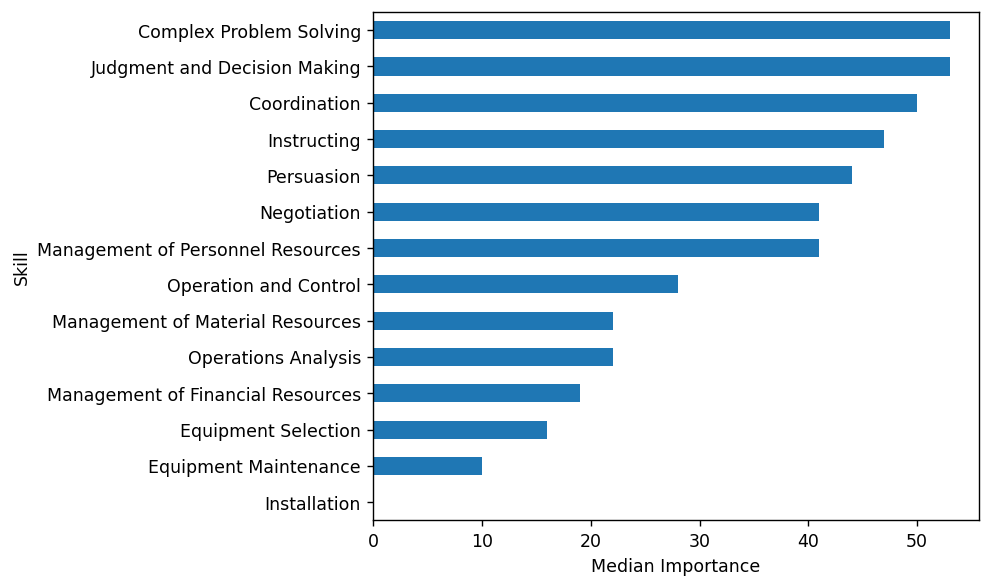

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from threadpoolctl import threadpool_limits

feature_table = eda.pivot(index='Code', columns='Skill', values='Importance')
assert feature_table.shape == (910, 14) and not feature_table.isna().any().any()
print(feature_table.shape)
feature_table.median().sort_values().plot.barh(figsize=(8, 4.8), xlabel='Median Importance')
plt.tight_layout()
plt.show()


## 3. Calculate inertia for each K

Following Case Study - Customer Segmentation.ipynb, set X, loop over K and store each fitted model’s inertia in ssd. This unsupervised EDA uses the 14 standardised Importance features (X) for all 910 occupations. There is no target label y for finding occupation groups. The separate CV evidence classifier has a labelled target and uses train, validation, and test splits.

In [3]:
# The classroom example sets X, loops over K, and stores each model's inertia.
wide = feature_table
X = StandardScaler().fit_transform(wide.to_numpy())
ks = np.arange(1, 11)
ssd = []

with threadpool_limits(limits=1):
    for k_candidate in ks:
        kmeans = KMeans(n_clusters=int(k_candidate), n_init=20, random_state=42)
        kmeans.fit(X)
        ssd.append(kmeans.inertia_)

inertia = np.array(ssd)
# Measure distance below the endpoint chord on normalized axes.
x_scaled = (ks - ks.min()) / (ks.max() - ks.min())
y_scaled = (inertia - inertia[-1]) / (inertia[0] - inertia[-1])
elbow_distance = (1 - x_scaled - y_scaled) / np.sqrt(2)
elbow_k = int(ks[elbow_distance.argmax()])
# Use four groups to show Resource Management and Team Coordination separately.
k = 4

comparison = []
with threadpool_limits(limits=1):
    for candidate_k in (3, 4):
        reference = KMeans(n_clusters=candidate_k, n_init=20, random_state=42).fit(X)
        repeat = KMeans(n_clusters=candidate_k, n_init=20, random_state=7).fit(X)
        comparison.append({
            'K': candidate_k,
            'Inertia': reference.inertia_,
            'RMS centroid distance': np.sqrt(reference.inertia_ / len(X)),
            'Silhouette': silhouette_score(X, reference.labels_),
            'ARI (seeds 42 and 7)': adjusted_rand_score(reference.labels_, repeat.labels_),
        })
        if candidate_k == k:
            model = reference

yhat = model.labels_
print(f'Elbow K: {elbow_k} | Selected K: {k}')
print(pd.DataFrame(comparison).set_index('K').to_string(float_format='{:.3f}'.format))
print()
print(pd.DataFrame({'K': ks, 'inertia': ssd, 'elbow_distance': elbow_distance})
      .round(3).to_string(index=False))

cluster_names = {
    1: 'Resource Management and Team Coordination',
    2: 'Coordination and Practical Decisions',
    3: 'Equipment Operation and Maintenance',
    4: 'Problem Solving and Instruction',
}


Elbow K: 3 | Selected K: 4
   Inertia  RMS centroid distance  Silhouette  ARI (seeds 42 and 7)
K                                                                  
3 6817.887                  2.737       0.249                 1.000
4 5880.141                  2.542       0.220                 0.997

 K   inertia  elbow_distance
 1 12740.000           0.000
 2  8142.454           0.296
 3  6817.887           0.325
 4  5880.141           0.322
 5  5387.414           0.284
 6  4949.196           0.241
 7  4612.880           0.190
 8  4364.932           0.131
 9  4191.589           0.067
10  4049.233           0.000


## 4. Elbow curve and choice of four profiles

The curve bends across K = 3–4. Both are reasonable choices from the plot. We selected K = 4 because it reveals a distinct Resource Management and Team Coordination profile. At K = 4, inertia is 13.8% lower and root-mean-square distance to the assigned centroid is 2.54 rather than 2.74 in standardised feature space. Silhouette falls by 0.029, indicating slightly more overlap. ARI compares assignments across seeds 42 and 7 for each K. The reported ARIs support stability across these two starts on the same occupations. Inertia depends on the dataset and generally falls as K increases. There is no universal distance cutoff for overfitting, and seed agreement alone does not establish stability on new samples.

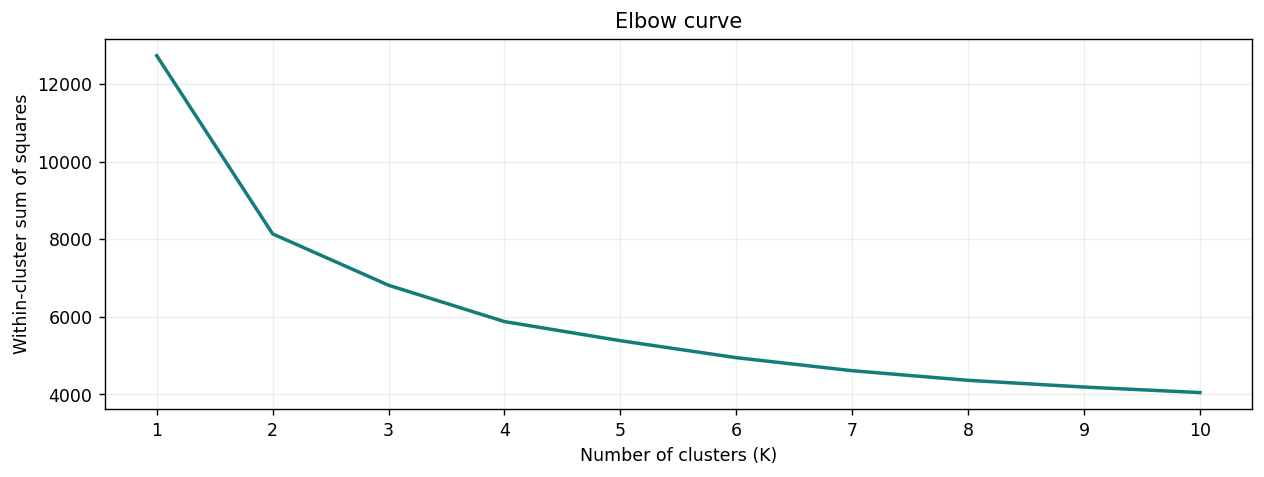

In [4]:
fig = plt.figure(figsize=(10, 3.7), layout='constrained')
plt.plot(ks, ssd, color='#147D79', linewidth=2)
plt.xticks(ks)
plt.ylabel('Within-cluster sum of squares')
plt.xlabel('Number of clusters (K)')
plt.grid(True, alpha=.2)
plt.title('Elbow curve')
plt.show()


## 5. Name and visualise the clusters

Name each cluster using the original-scale skill ratings and representative occupations nearest the centroid. For Cluster 2, the name reflects its highest-rated skills, Coordination (46.0) and Judgment and Decision Making (45.0), even though both are below the overall averages. PCA projects the standardised features into two dimensions for visualisation.

Cluster 1: Resource Management and Team Coordination (128 occupations)
  Highest average Importance: {'Judgment and Decision Making': 68.0, 'Coordination': 67.2, 'Complex Problem Solving': 66.1, 'Management of Personnel Resources': 60.0}
  Differences from overall averages: {'Management of Financial Resources': 21.7, 'Management of Personnel Resources': 20.3, 'Management of Material Resources': 18.9, 'Negotiation': 16.5}
  Representative occupations: Meeting, Convention, and Event Planners; Architectural and Engineering Managers; Transportation, Storage, and Distribution Managers
Cluster 2: Coordination and Practical Decisions (214 occupations)
  Highest average Importance: {'Coordination': 46.0, 'Judgment and Decision Making': 45.0, 'Complex Problem Solving': 41.5, 'Persuasion': 35.0}
  Differences from overall averages: {'Operation and Control': -3.8, 'Installation': -5.2, 'Equipment Maintenance': -6.2, 'Equipment Selection': -6.5}
  Representative occupations: Parking Attendants; Je

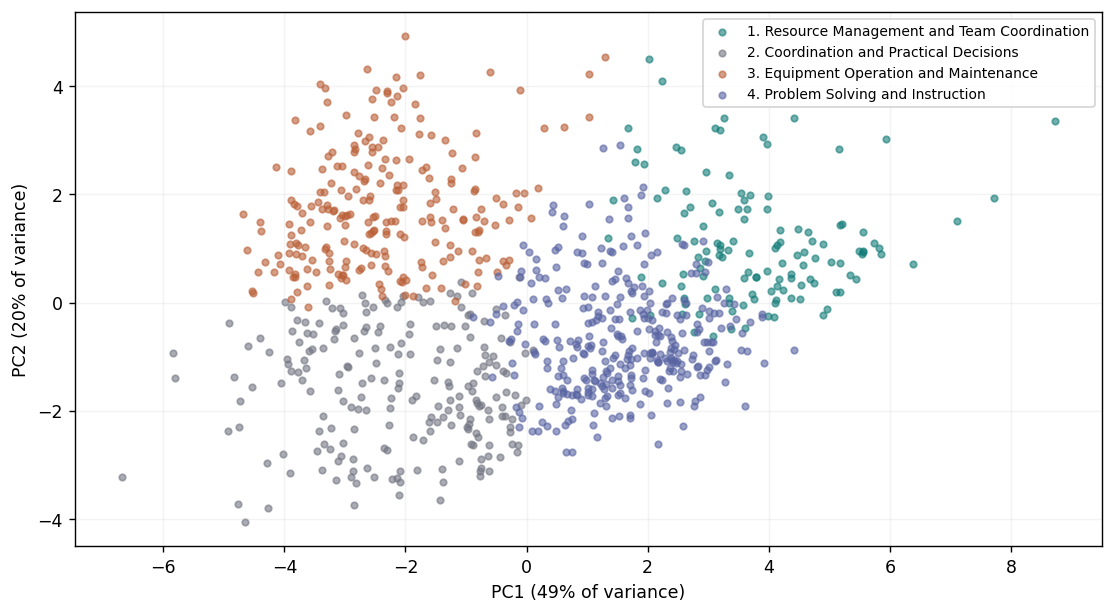

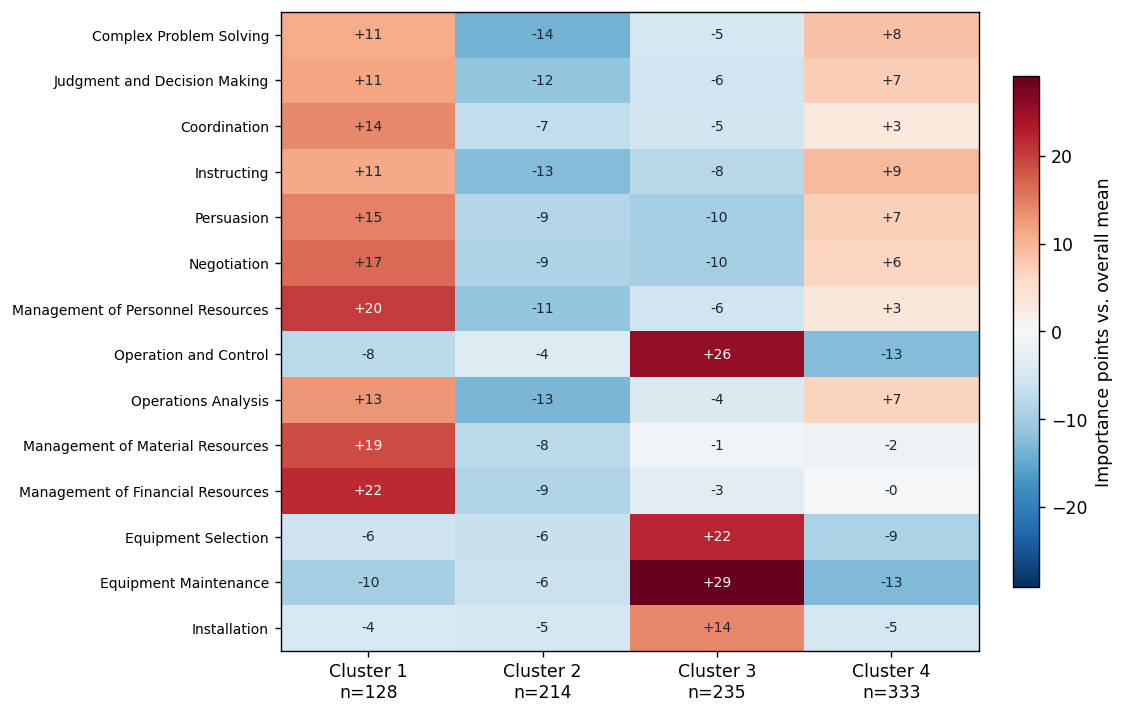

In [5]:
baseline=wide.mean()
profiles=wide.groupby(yhat+1).mean()
sizes=pd.Series(yhat+1).value_counts().sort_index()
metadata=eda.drop_duplicates('Code').set_index('Code').reindex(wide.index)
meta=metadata.assign(cluster=yhat+1,major=metadata.index.str[:2])
examples={}
for i in profiles.index:
 positions=(yhat==i-1).nonzero()[0]
 distances=model.transform(X[positions])[:,i-1]
 examples[i]=meta.iloc[positions[distances.argsort()[:3]]].Occupation.tolist()
 print(f'Cluster {i}: {cluster_names[i]} ({sizes[i]} occupations)')
 print('  Highest average Importance:', profiles.loc[i].nlargest(4).round(1).to_dict())
 print('  Differences from overall averages:',
       (profiles.loc[i]-baseline).nlargest(4).round(1).to_dict())
 print('  Representative occupations:', '; '.join(examples[i]))
print('major group count',meta.major.nunique())
pca = PCA(n_components=2)
projected = pca.fit_transform(X)
fig,ax=plt.subplots(figsize=(8.8,4.8),layout='constrained')
for i,color in zip(profiles.index,['#147D79','#737683','#BA6037','#5965A3']):
 points = projected[yhat==i-1]
 ax.scatter(*points.T,s=14,alpha=.6,label=f'{i}. {cluster_names[i]}',color=color)
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)')
ax.legend(fontsize=8);ax.grid(alpha=.15)
plt.show()
diff=(profiles-baseline).T.reindex(wide.median().sort_values(ascending=False).index)
limit=max(abs(diff.min().min()),abs(diff.max().max()))
fig,ax=plt.subplots(figsize=(8.9,5.6),layout='constrained')
im=ax.imshow(diff,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
ax.set_xticks(range(k),[f'Cluster {i}\nn={sizes[i]}' for i in diff.columns])
ax.set_yticks(range(len(diff)),diff.index,fontsize=8)
for y in range(len(diff)):
 for x in range(k):
    value=diff.iloc[y,x];ax.text(x,y,f'{value:+.0f}',ha='center',va='center',color='white' if abs(value)>.6*limit else '#182537',fontsize=8)
fig.colorbar(im,ax=ax,shrink=.8,label='Importance points vs. overall mean')
plt.show()


## Uneven cluster sizes

The K = 4 groups contain 128 to 333 occupations. Larger groups have more influence on the overall mean used as a reference in the heatmap. K = 3 has a smaller largest-to-smallest ratio and a higher silhouette score. K = 4 gives a separate resource-management profile. These are descriptive group sizes in the O*NET file.

In [6]:
from collections import Counter

# Compare group sizes using the same standardised features and fitting settings.
with threadpool_limits(limits=1):
    comparison_k3 = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X)
members_k3 = sorted(Counter(comparison_k3.labels_).values())
members_k4 = pd.Series(model.labels_ + 1).value_counts().sort_index()
assert list(members_k4) == [128, 214, 235, 333]
assert members_k4.sum() == len(X)
print('K = 3, sorted counts:', members_k3)
print('K = 4, counts by cluster:', members_k4.to_dict())
print('K = 4, percentage by cluster:', (100 * members_k4 / len(X)).round(1).to_dict())
print('Largest to smallest ratios:', round(max(members_k3)/min(members_k3), 2),
      'for K = 3,', round(members_k4.max()/members_k4.min(), 2), 'for K = 4')


K = 3, sorted counts: [248, 252, 410]
K = 4, counts by cluster: {1: 128, 2: 214, 3: 235, 4: 333}
K = 4, percentage by cluster: {1: 14.1, 2: 23.5, 3: 25.8, 4: 36.6}
Largest to smallest ratios: 1.65 for K = 3, 2.6 for K = 4
